In [199]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [200]:
df = pd.read_csv("credit_risk_dataset.csv")
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [201]:
df.shape
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
None


In [202]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [203]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [204]:
df['loan_status'].unique()

array([1, 0])

In [205]:
df['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

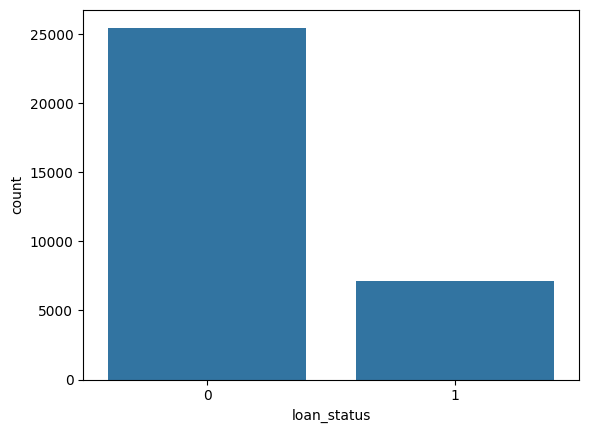

In [206]:
sns.countplot(x='loan_status', data = df)

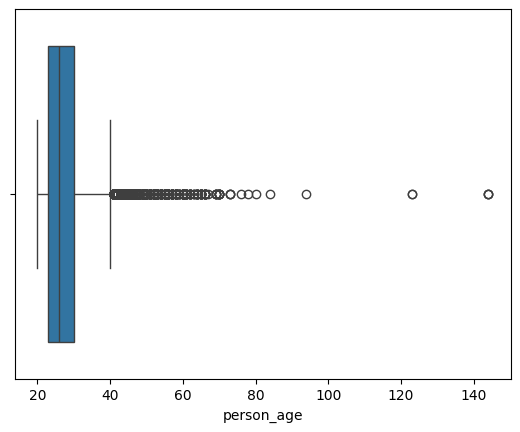

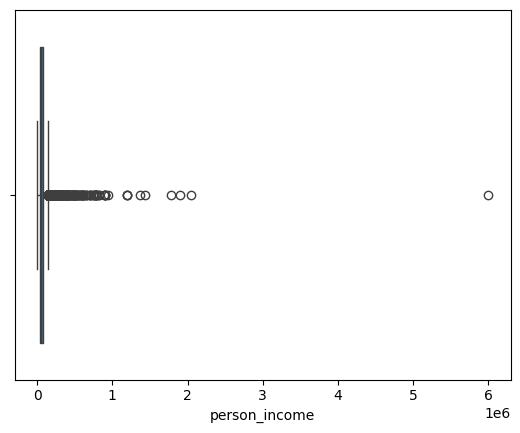

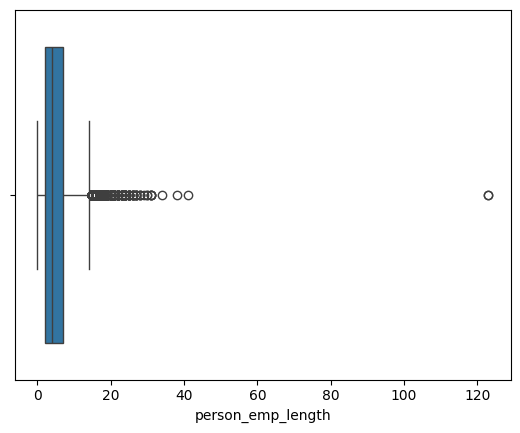

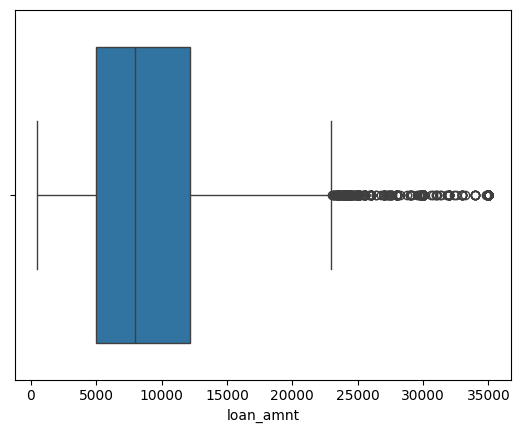

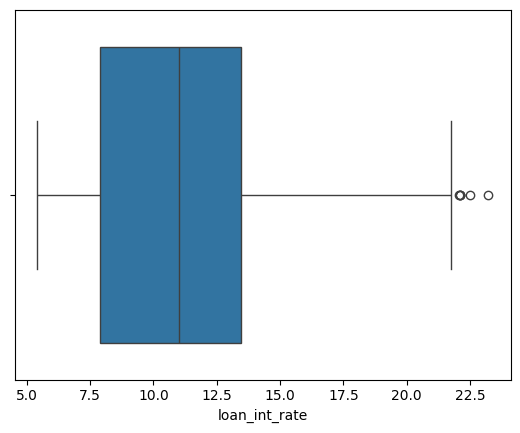

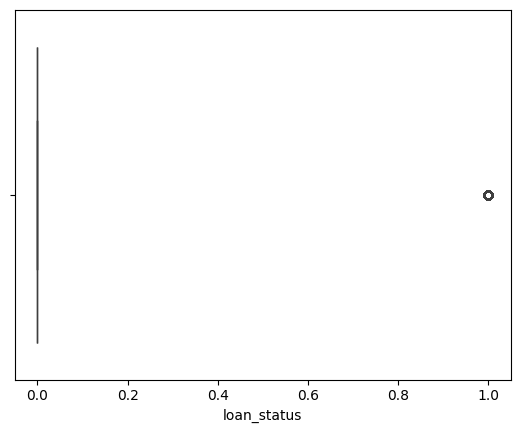

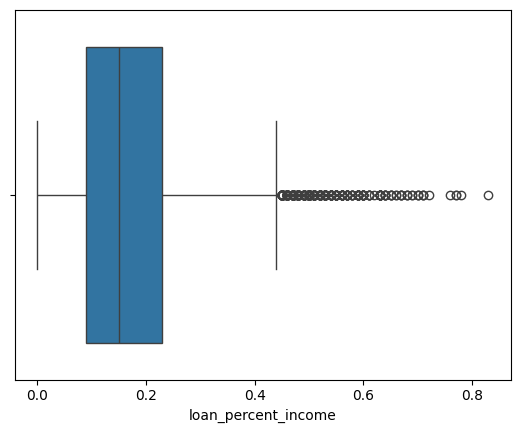

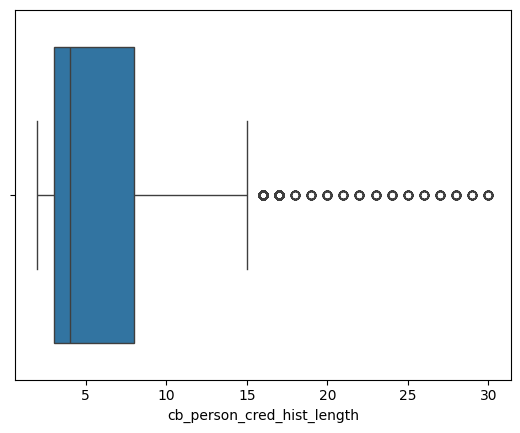

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length'],
      dtype='object')

In [207]:
numerical_cols = df.select_dtypes(include=np.number).columns
for i in numerical_cols:
  sns.boxplot(x=df[i])
  plt.show()

numerical_cols


In [208]:
(df['person_age'] > 100).sum()

np.int64(5)

In [209]:
(df['person_emp_length']>60).sum()

np.int64(2)

In [210]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


**Correlation** **Check**

*   See how strongly features are related to each other
*   This helps us spot repeated or linked information



<Axes: >

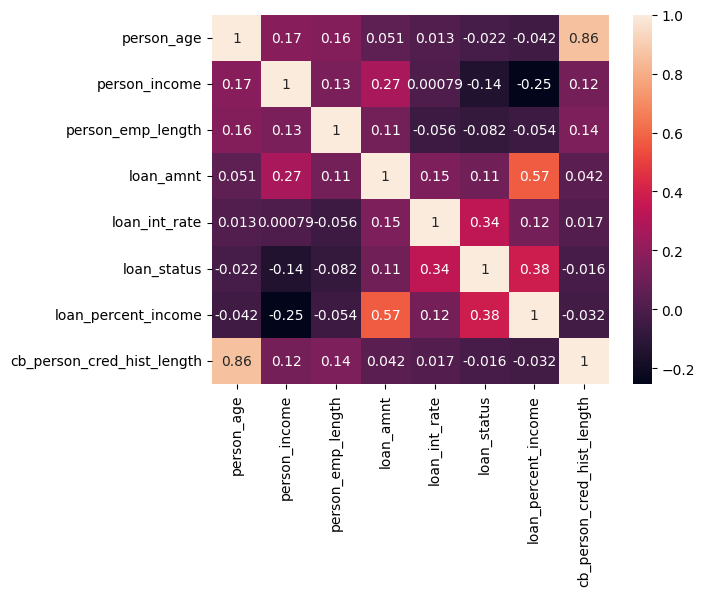

In [211]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

**Data Validation and Outlier Handling**


*   Here we clean the data properly
*   We remove duplicate rows
*   We remove rows with an impossible age or work experience.
*   We remove rows with zero or negative income and loan amount

*   We check if the interest rate looks realistic
*   We also flag rows where numbers don't add up correctly.







In [212]:
df_copy = df.copy()
print(f"Original Rows: {df_copy.shape[0]}")

#Remove Duplicate rows
df_copy.drop_duplicates(inplace=True)
print(f"After Removing Duplicates: {df_copy.shape[0]}")

#Remove ages below 18 or above 100
df_copy = df_copy[df_copy['person_age'] >=18]
df_copy = df_copy[df_copy['person_age'] <= 100]

print("Shape after Age Removal: ",df_copy.shape);

#Remove employment length greater than age or extreme outliers (>60)
df_copy = df_copy[df_copy['person_emp_length']<= df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length'] <= 60]
print(f"Shape after Removal of employment length: {df_copy.shape}");

#Remove the rows with zero or negative income and loan amount
df_copy = df_copy[df_copy['loan_amnt']>0]
print(f"Shape after removal of loan amount: {df_copy.shape}");

#Check if the interest rate looks realistic
print("Loan interest rate range from(min: 5.42 and max: 23.22)")

Original Rows: 32581
After Removing Duplicates: 32416
Shape after Age Removal:  (32411, 12)
Shape after Removal of employment length: (31522, 12)
Shape after removal of loan amount: (31522, 12)
Loan interest rate range from(min: 5.42 and max: 23.22)


**Features, Target and Train_Test Split**


*   We separate the data into input features and the target
*   The target is whether the applicant defaulted or not


*   We split the data into a training part and a testing part
*   The model learns from the training part only





In [213]:
X = df_copy.drop('loan_status', axis= 1)
y = df_copy['loan_status']

In [214]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

In [215]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                     'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


**Handle Class Imbalance**


*   Very few people actually default in this data
*   If we ignore this, the model may just favor the majority class


*   We give more importance to the minority calss during training
*   This helps the model actually learn to spot defaulters





In [216]:
#0 -> no loan (mostly in dataset)
#1 -> yes loan

neg, pos = np.bincount(y_train)
scale_weights = neg/pos

In [217]:
print(f"Scale_weights: {scale_weights}")

Scale_weights: 3.6312213039485766


**Data Preprocessing — Pipelines & Column Transformer**


*   Raw data is not ready for a model directly.
*   We need to prepare numeric and text columns differently.


*  We will build a Pipeline for each model
*   We will use ColumnTransformer to apply different steps to different columns.





**Preprocessing for Logistic Regression**
* Fill missing numeric values.
* Scale numeric values, since this model is sensitive to scale.
* Convert category columns into numbers using one-hot encoding.





In [218]:
#Logistic Regression : impute + scale Numeric, impute + One-Hot-Encoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor_lr = ColumnTransformer(
    transformers=[
        #pipeline for numerical cols
        ('num', Pipeline(
            [
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())
            ]
        ), numeric_cols),
        #Pipeline for Categorical cols
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy = "constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)


**Preprocessing for XGBoost**
* Fill missing numeric values.
* No scaling needed here, since tree models don't need it.
* Convert category columns into numbers using one-hot encoding.

In [219]:
#XGBoost: Imputer Numeric only (No scaling), impute + One-Hot Encoding

preprocessor_xg = ColumnTransformer(
    transformers=[
        #pipeline for numerical cols
        ('num', Pipeline(
            [
                ('imputer', SimpleImputer(strategy='median')),

            ]
        ), numeric_cols),
        #Pipeline for Categorical cols
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy = "constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

**Evaluation Helper Function**
* We build one common function to check any model's performance.
* It will show accuracy, precision, recall, F1 score, and more.
* It will also show a confusion matrix and a precision-recall curve.

In [220]:
#We have to evaluate Logistic Model and XGBoost model on the basis of their metrics

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, precision_recall_curve
def evaluate_model(model_name, model, X_test, y_test, threshold=None):
  y_pred_prob = model.predict_proba(X_test)[:,1]

  if threshold:
    y_pred = (y_pred_prob >= threshold).astype(int)
  else:
    y_pred = model.predict(X_test)

    #metrics

  accuracy = accuracy_score(y_test, y_pred) #Overall model's performance
  precision = precision_score(y_test, y_pred, zero_division=0) #When the model says 1, how oftenly is it actually 1.
  recall = recall_score(y_test, y_pred, zero_division=0) #of the actual 1 how many did the model catches
  f1 = f1_score(y_test, y_pred, zero_division=0)
  conf_matrix = confusion_matrix(y_test, y_pred)
  class_report = classification_report(y_test, y_pred)

  print(f"{model_name} Metrics:")
  if threshold is not None: #Only print threshold if provided
      print(f"Threshold: {threshold:.2f}")
  print(f"Accuracy: {accuracy: .2f}")
  print(f"Precision: {precision: .2f}")
  print(f"Recall: {recall: .2f}")
  print(f"F1: {f1}")
  print()
  print(f"{model_name} Classification Report:")
  print(class_report)

    #Plotting confusion matrix
  sns.heatmap(conf_matrix, annot=True, fmt="d")
  plt.title(f"{model_name} Confusion Matrix")
  plt.ylabel("Actual Values")
  plt.xlabel("Predicted Values")
  plt.show()


  #Plotting ROC-AUC curve
  precisions, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
  plt.plot(recalls, precisions)
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title(f"{model_name} Precision-Recall Curve")
  plt.show()

**Stratified Cross-Validation**
* One single train-test split may not be reliable.
* We split the training data into five folds instead.
* Each fold keeps the same default vs repaid ratio.
* We check the model's score across all folds.


In [221]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

scoring = {'roc_auc':'roc_auc', 'accuracy':'accuracy', 'precision': 'precision', 'recall':'recall', 'f1':'f1'}


In [222]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

In [223]:
#XGBoost Model
from xgboost import XGBClassifier
Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                                 scale_pos_weight=scale_weights, random_state= 42))
])

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [224]:
#XGBoost Model
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(n_estimator=300, max_depth=5, learning_rate=0.1,
                                 scale_pos_weight=scale_weights, random_state= 42))
])

In [225]:
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ("XGBClassifier", xgb_cv_pipeline)]:
                      #print(cv_name, pipe)
                      cv_results = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
                      print(cv_name)
                      print(f"ROC_AUC: {cv_results['test_roc_auc'].mean()}")
                      print(f"Accuracy: {cv_results['test_accuracy'].mean()}")
                      print(f"Precision: {cv_results['test_precision'].mean()}")
                      print(f"Recall: {cv_results['test_recall'].mean()}")
                      print(f"F1: {cv_results['test_f1'].mean()}")



Logistic Regression
ROC_AUC: 0.8705112830525306
Accuracy: 0.8115949542892269
Precision: 0.5448226008889892
Recall: 0.7781450872359963
F1: 0.6408013995933108
XGBClassifier
ROC_AUC: 0.9393848243386111
Accuracy: 0.9086724038455642
Precision: 0.7913354492271174
Recall: 0.7856749311294765
F1: 0.7880291923045915


In [226]:
cv_results

{'fit_time': array([0.35259366, 0.35553694, 0.34722757, 0.34767985, 0.23489594]),
 'score_time': array([0.06742311, 0.07353878, 0.07077193, 0.09079218, 0.04271317]),
 'test_roc_auc': array([0.94306506, 0.93043619, 0.94080108, 0.94479977, 0.93782203]),
 'test_accuracy': array([0.9129659 , 0.91237113, 0.90838786, 0.9109657 , 0.89867143]),
 'test_precision': array([0.80545113, 0.82317682, 0.79000925, 0.78933092, 0.74870912]),
 'test_recall': array([0.78696051, 0.75665748, 0.78420569, 0.80165289, 0.79889807]),
 'test_f1': array([0.79609847, 0.78851675, 0.78709677, 0.79544419, 0.77298978])}

**Baseline Model — Logistic Regression**
* We start with a simple model first.
* This becomes our benchmark to beat.
* We train it and check its score on the test data.

In [227]:
from sklearn.pipeline import Pipeline
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(class_weight = "balanced"))
])

baseline_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

 **XGBoost Hyperparameter Tuning**
* Now we move to a stronger model, XGBoost.
* A model has many settings called hyperparameters.
* We search for the best combination of these settings.
* We use cross-validation while searching, so the result is reliable.

In [228]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier',XGBClassifier(learning_rate = 0.1, scale_pos_weight=scale_weights, random_state=42))

])
xg_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

Baseline Logistic Model Metrics:
Accuracy:  0.82
Precision:  0.56
Recall:  0.79
F1: 0.6530612244897959

Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



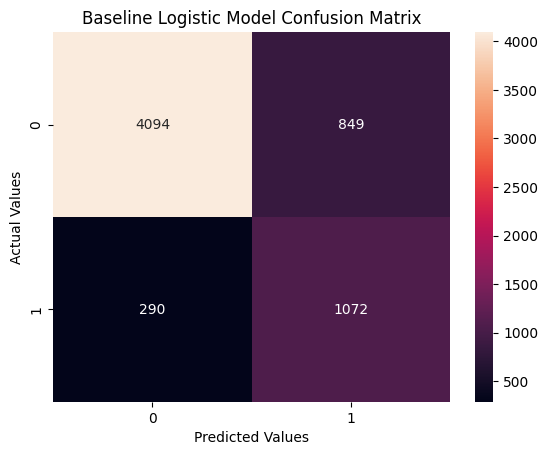

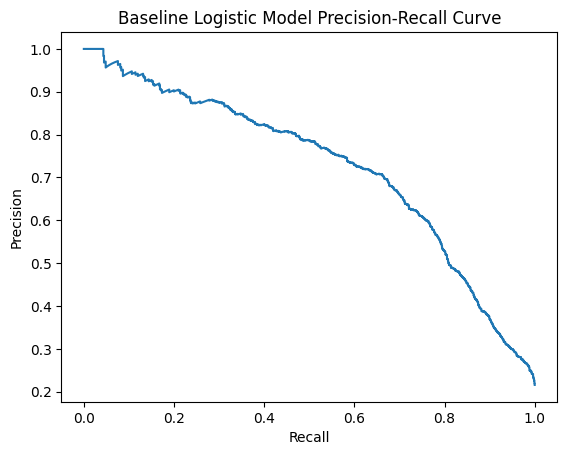

In [229]:
evaluate_model("Baseline Logistic Model", baseline_model, X_test, y_test)

XGBoost Metrics:
Accuracy:  0.92
Precision:  0.82
Recall:  0.79
F1: 0.8082242990654206

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305



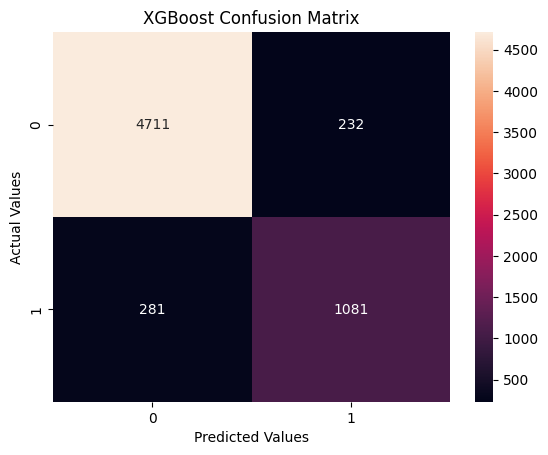

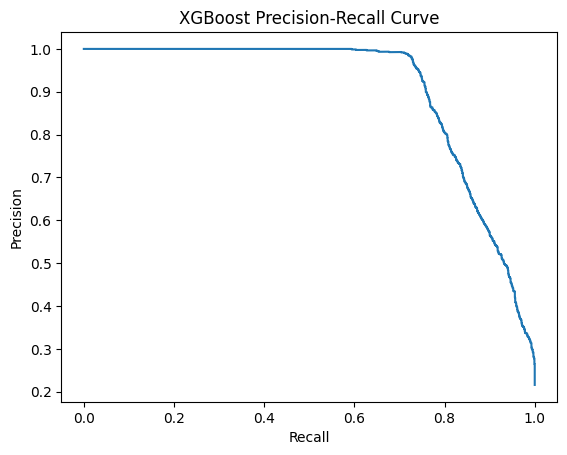

In [230]:
evaluate_model("XGBoost", xg_model, X_test, y_test)

In [231]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth": randint(3,9),
    "classifier__learning_rate": uniform(0.01, 0.5),
    "classifier__subsample": uniform(0.6, 0.4), #Rows sampling
    "classifier__colsample_bytree": uniform(0.6, 0.4), #column sampling
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0.5)

}

#lower gamma -> more splits -> complex tree -> higher overfitting risk
# higher gamma -> less splits -> simpler tree -> lower overfitting

In [ ]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter = 150,
    cv = cv,
    scoring = "average_precision",
    n_jobs = -1,
    verbose = 1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


In [ ]:
print(f"Score after performing Tunning {random_search.best_score_:.2f}")

In [ ]:
random_search.best_params_

 **Compare Both Models Side by Side**
* We now compare Logistic Regression and XGBoost.
* We look at their scores together in one table.
* This helps us pick the better performing model.

In [ ]:
evaluate_model("Logistic Regression", baseline_model, X_test, y_test)

In [ ]:
#Passing the XGBoost after performing Hyperparameter Tuning
evaluate_model("XGBoost", random_search, X_test, y_test)

 **Optimizing the Classification Threshold**
* The model gives a probability, not a direct yes or no.
* We decide a cut-off point to turn it into a decision.
* We check different cut-off points and pick the best one.

In [ ]:
#Get the prob. of class 1 from XGBoost
prob = xg_model.predict_proba(X_test)[:, 1]

#For each threshold calculate Precision and Recall
precisions, recalls , thresholds = precision_recall_curve(y_test, prob)


#Calculate F1 score for each threshold
f1 = 2 * (precisions*recalls) / (precisions + recalls + 1e-9)

#Get the threshold that produces the highest f1-score
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

#Evaluate the XGBoost model using that threshold.
evaluate_model("XGBoost", xg_model, X_test, y_test, best_threshold)

**Probability Calibration**
* Sometimes a model's probability doesn't mean what it says.
* For example, 30% risk should truly mean a 30% chance.
* We check this with a calibration plot.
We fix it if the probabilities are off.


In [ ]:
"""
Methods by which we can fix the poorly calibrated model
1. Platt Scaling / Sigmoid -> Adjust the probabilities using a sigmoid curve.
2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibration)
3. Temperature Scaling -> Adjust the confidence of  neural-network predictions using one temperature
"""

In [ ]:
#1. Calibrated XGBoost model
from sklearn.calibration import  CalibratedClassifierCV, calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    method = "sigmoid",
    cv = 5
)
calibrated_model.fit(X_train, y_train)

In [ ]:
#Get probabilities
uncalibrated = xg_model.predict_proba(X_test)[:,1]
calibrated = calibrated_model.predict_proba(X_test)[:, 1]

In [ ]:
#3. Create calibration curves
actual_uncal, predicted_uncal = calibration_curve(y_test, uncalibrated, n_bins = 10)

In [ ]:
actual_cal, predicted_cal = calibration_curve(y_test, calibrated, n_bins=10)

In [ ]:
#4. plot
plt.plot([0, 1], [0, 1], 'k--', label = "Perfect")
plt.plot(predicted_uncal,
         actual_uncal,
         "o-",
         label = "Uncalibrated")
plt.plot(
    predicted_cal,
    actual_cal,
    "o-",
    label = "Calibrated"
)
plt.legend()

In [259]:
#Get the probabilities from the CALIBRATED model, not the old xg_model
from sklearn.metrics import precision_recall_curve
import numpy as np
calibrated_proba = calibrated_model.predict_proba(X_test)[:,1]

# Re-run the same threshold search, now on the correct probability scale

precisions, recalls, thresholds = precision_recall_curve(y_test, calibrated_proba)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)
best_threshold = thresholds[np.argmax(f1_scores[:-1])]

print("New threshold: ", best_threshold)

New threshold:  0.7354983135770726


**SHAP Interpretation — Global & Local**
* SHAP helps us understand why the model makes a decision.
* It is a way of explaining a "black box" model.


In [245]:
#1. Install SHAP if not exists
!pip install shap
import shap

In [246]:
#2. Get the Trained XGBoost classifier models out of the pipeline.
xgb_classifier = xg_model.named_steps['classifier']

In [247]:
#3. Transform X_test using the same preprocessing used-for training
X_test_transformed = xg_model.named_steps['preprocessor'].transform(X_test)

In [248]:
#4. Get feature names after one-hot encoding, so plots are readable
feature_names = xg_model.named_steps['preprocessor'].get_feature_names_out()
feature_names

array(['num__person_age', 'num__person_income', 'num__person_emp_length',
       'num__loan_amnt', 'num__loan_int_rate', 'num__loan_percent_income',
       'num__cb_person_cred_hist_length',
       'cat__person_home_ownership_MORTGAGE',
       'cat__person_home_ownership_OTHER',
       'cat__person_home_ownership_OWN',
       'cat__person_home_ownership_RENT',
       'cat__loan_intent_DEBTCONSOLIDATION', 'cat__loan_intent_EDUCATION',
       'cat__loan_intent_HOMEIMPROVEMENT', 'cat__loan_intent_MEDICAL',
       'cat__loan_intent_PERSONAL', 'cat__loan_intent_VENTURE',
       'cat__loan_grade_A', 'cat__loan_grade_B', 'cat__loan_grade_C',
       'cat__loan_grade_D', 'cat__loan_grade_E', 'cat__loan_grade_F',
       'cat__loan_grade_G', 'cat__cb_person_default_on_file_N',
       'cat__cb_person_default_on_file_Y'], dtype=object)

In [249]:
#5. Convert to a dataframe for cleaner SHAP plots
X_test_df = pd.DataFrame(X_test_transformed, columns= feature_names)
X_test_df

,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,...,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,24.0,30000.0,1.0,15000.0,15.68,0.50,3.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,23.0,60000.0,6.0,25600.0,10.99,0.43,4.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,29.0,18000.0,2.0,3600.0,15.27,0.20,6.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,32.0,130000.0,7.0,13000.0,12.69,0.10,8.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,23.0,45288.0,7.0,20500.0,9.25,0.45,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6300,21.0,75000.0,5.0,20000.0,13.11,0.27,2.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
6301,29.0,265000.0,2.0,25000.0,11.26,0.09,10.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6302,25.0,48996.0,8.0,5000.0,9.88,0.10,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6303,27.0,115000.0,11.0,8000.0,7.51,0.07,7.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [250]:
#6. Create SHAP explainer built for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)


In [251]:
#7. Calculate SHAP  values for every row in the test set
shap_values = explainer.shap_values(X_test_df)
shap_values

array([[-1.7525564e-01, -1.0555401e-01,  1.2984274e-01, ...,
        -7.3516299e-03, -3.8879909e-02,  0.0000000e+00],
       [ 4.7165085e-02, -8.7262326e-01, -9.4737314e-02, ...,
        -9.2151780e-03, -7.5508673e-03,  0.0000000e+00],
       [ 7.8027323e-02,  3.5025654e+00,  1.2711690e-01, ...,
        -7.3584518e-03,  7.7456667e-04,  0.0000000e+00],
       ...,
       [-8.6244913e-03,  5.8208084e-01,  7.2391242e-02, ...,
        -9.2837382e-03, -1.1459960e-02,  0.0000000e+00],
       [ 2.0838849e-02, -1.0313793e+00,  4.3692421e-02, ...,
        -9.2305308e-03, -1.1398584e-02,  0.0000000e+00],
       [-1.3665082e-01, -5.0866711e-01,  2.6854105e-02, ...,
        -8.8342456e-03, -1.0388625e-02,  0.0000000e+00]], dtype=float32)

**Global explanation**
* This shows which features matter most overall.
* It also shows if a feature increases or decreases risk.

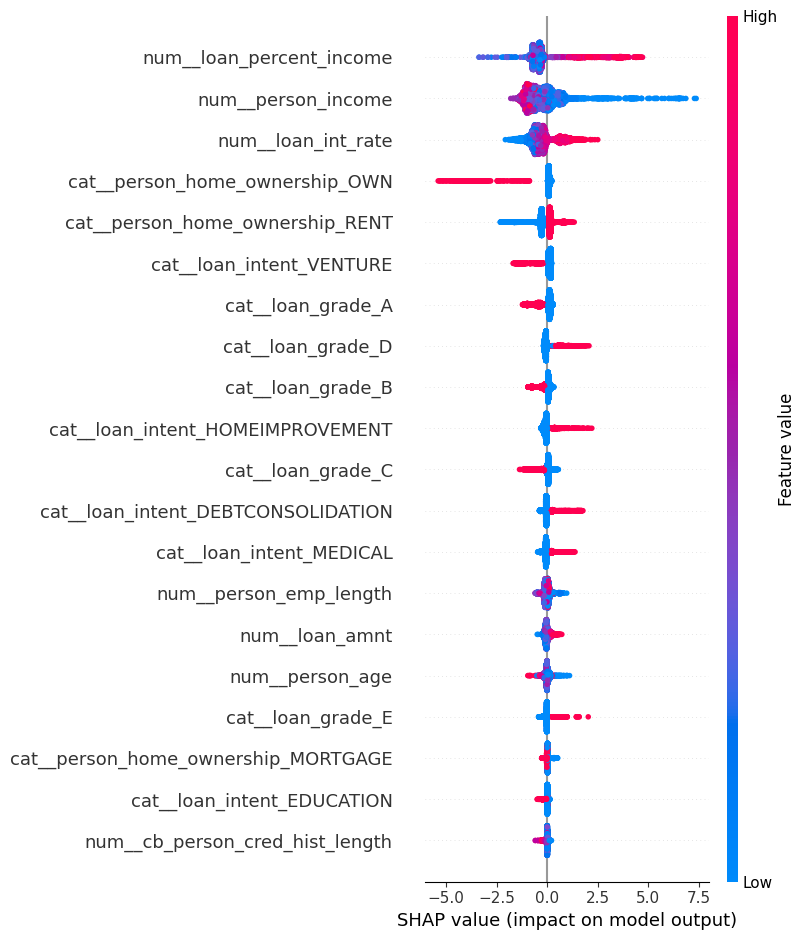

In [252]:
shap.summary_plot(shap_values, X_test_df)

**Local explanation**
* This shows why one specific applicant got their score.
* It breaks the score down feature by feature.

In [253]:
#1. Pick one row to explain, e.g. the 5th applicant in the test set
row_index = 5

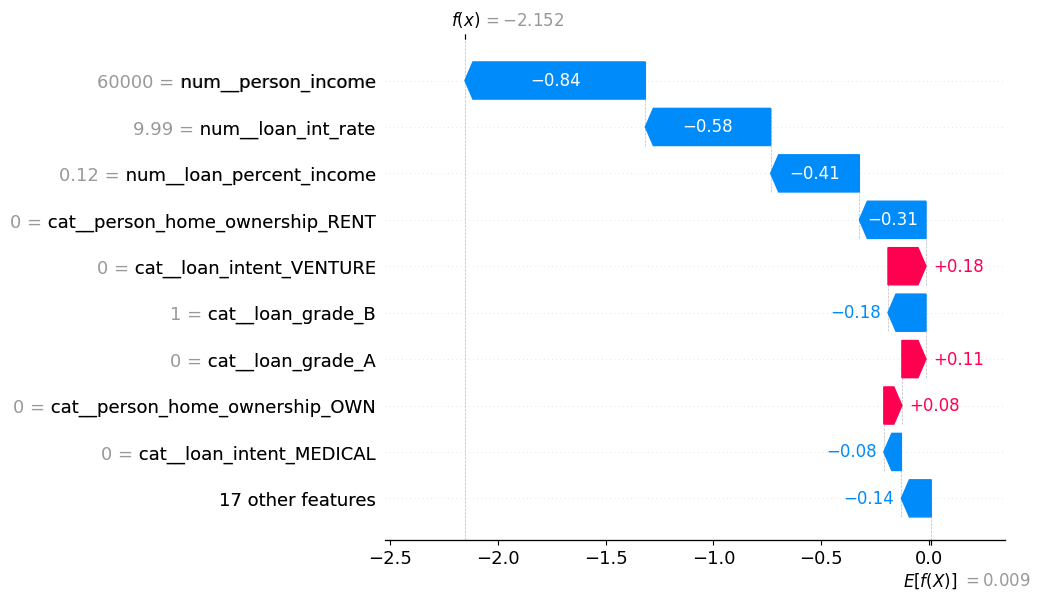

In [254]:
#2. Draw a waterfall plot showing how each features pushed the prediction up or down
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = feature_names
    )
)

 **Analyzing False Positives & False Negatives**
* The model will not be perfect.
* False positives are safe people wrongly marked risky.
* False negatives are risky people wrongly marked safe.
* We study these cases to understand where the model struggles.

In [255]:
#Get predictions from the best performing XGBoost model on the test set
y_pred = random_search.predict(X_test)

In [256]:
#Create a dataframe to easily compare the actual and predicted values
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [257]:
#Identify False Positive: Model Predicted 1, but the actual was 0
false_positive = result_df[(result_df['actual'] == 0)&(result_df['predicted']==1)]
#Identify False Negative: Model Predicted 0, but the actual was 1
false_negative = result_df[(result_df['actual']==1)&(result_df['predicted'] == 0)]

In [258]:
print(f"False Positive: {len(false_positive)}")
print(f"False Negative: {len(false_negative)}")

False Positive: 242
False Negative: 262


**Save the Final Model**
* Once we are happy with the model, we save it.
* We also save the settings it needs, like the chosen threshold.
* This saved file can now be used in a real application.

In [260]:
import joblib
joblib.dump(calibrated_model, "credit_risk_model.pkl")

['credit_risk_model.pkl']

In [261]:
joblib.dump(best_threshold, "best_threshold.pkl")

['best_threshold.pkl']